# import lib

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
start_path = "./debug_test1_new_boxes_detection02"  # Update this path to your new output directory
results_file = f"{start_path}/summary.csv"
ocr_file = f"{start_path}/ocr_results.csv"
# Load results
results_df = pd.read_csv(results_file)
ocr_df = pd.read_csv(ocr_file)

In [3]:
len(results_df), len(ocr_df)

(19, 19)

In [4]:
dni_zone = results_df.copy()
ocr_results = ocr_df.copy()

In [5]:
print(f"max page: {dni_zone['page'].max()}")
print(f"num unique DNI predected:{ocr_results['predicted_dni'].nunique()}")
print(f"num of duplicate predicted DNI:{ocr_results['predicted_dni'].duplicated().sum()}")

max page: 109
num unique DNI predected:19
num of duplicate predicted DNI:0


In [6]:
dni_zone.head()

,page,dni_anchor_x0,dni_anchor_y0,dni_anchor_x1,dni_anchor_y1,annotated_image,box_1,box_2,box_3,box_4,box_5,box_6,box_7,box_8,box_9
0,1,268,241,374,348,/home/ariouich/Bureau/valencia/Madrina/Asisten...,"(382, 241, 488, 348)","(488, 242, 595, 349)","(596, 243, 703, 350)","(703, 244, 809, 351)","(810, 245, 918, 352)","(918, 246, 1025, 352)","(1025, 247, 1131, 353)","(1132, 247, 1237, 354)","(1238, 248, 1345, 355)"
1,7,272,239,378,346,/home/ariouich/Bureau/valencia/Madrina/Asisten...,"(386, 239, 492, 346)","(492, 240, 600, 347)","(600, 242, 708, 348)","(708, 243, 814, 350)","(815, 244, 923, 351)","(923, 245, 1030, 352)","(1030, 246, 1136, 353)","(1136, 247, 1242, 354)","(1242, 248, 1349, 355)"
2,13,231,254,369,359,/home/ariouich/Bureau/valencia/Madrina/Asisten...,"(371, 253, 476, 359)","(477, 253, 584, 360)","(584, 254, 691, 360)","(692, 254, 798, 361)","(799, 254, 907, 361)","(907, 254, 1013, 361)","(1014, 254, 1120, 361)","(1120, 254, 1226, 361)","(1227, 254, 1334, 361)"
3,19,271,246,377,353,/home/ariouich/Bureau/valencia/Madrina/Asisten...,"(385, 246, 491, 353)","(491, 247, 598, 355)","(599, 248, 706, 355)","(706, 249, 813, 356)","(813, 250, 921, 357)","(921, 251, 1028, 358)","(1028, 251, 1134, 359)","(1135, 252, 1240, 360)","(1241, 253, 1347, 361)"
4,25,282,213,388,320,/home/ariouich/Bureau/valencia/Madrina/Asisten...,"(396, 213, 502, 320)","(502, 215, 610, 321)","(610, 216, 717, 323)","(717, 217, 824, 324)","(824, 218, 933, 325)","(933, 220, 1040, 327)","(1040, 221, 1146, 328)","(1146, 222, 1252, 329)","(1252, 223, 1359, 330)"


In [7]:
ocr_results.head()

,page,predicted_dni,prediction_digits,exception_occurred,ground_truth_dni,exact_match,best_student_dni,best_student_nombre,best_student_apellidos,best_student_ratio
0,1,474799541,474799541,False,NaN,NaN,47479954,Pablo,Gargallo Valera,0.888889
1,7,399272535,399272535,False,NaN,NaN,39937253,Izan,Lopez Macia,0.777778
2,13,482293772,482293772,False,NaN,NaN,48729372,Javier,Sánchez Flor,0.777778
3,19,218023558,218023558,False,NaN,NaN,21802355,Jorge,Garcia Cortés,0.888889
4,25,62867595,62867595,False,NaN,NaN,6286789,Emma,Sánchez Silaghi,0.750000


In [8]:
df = pd.read_csv(
    "/home/ariouich/Bureau/valencia/Madrina/OriginalVersion/P1_nov_para_jefferson/students_list.csv",
    encoding='latin-1',
    sep=';'
)


In [9]:
df.head()

,DNI,Nombre,Grupo,Titulación,Tipo de Matrícula,Convocatoria,Comentario Profesor,Condición,Nota final,Nota sin restricciones,...,Rec. P2,Rec. P1,Parcial 2,Parcial 1,CT_01,Poliformat (sobre 10),Prácticas (sobre 10),Retornables (sobre 10),ACTA,Unnamed: 21
0,20851815,"Abril Revert, Borja",1PARS3,190 Grado en Ingeniería de Tecnologías y Servi...,Ordinaria,1.0,NaN,C Convocatoria confirmada,"9,38","9,38",...,NaN,NaN,"9,1","9,25",NaN,"9,84",10,"9,81","9,4",NaN
1,26665047,"Abu-Taha Sabsoub, Nader",B1,190 Grado en Ingeniería de Tecnologías y Servi...,Ordinaria,1.0,NaN,C Convocatoria confirmada,"5,9","5,9",...,NaN,NaN,"5,55","5,05",NaN,"7,14","8,94","4,34","5,9",NaN
2,49570057,"Acedo Marzo, Unai",B2,190 Grado en Ingeniería de Tecnologías y Servi...,Ordinaria,1.0,NaN,C Convocatoria confirmada,6,6,...,NaN,NaN,"3,8","6,9",NaN,"7,65","8,29","8,04",6,NaN
3,73606454,"Agustina García, Sol",A3,190 Grado en Ingeniería de Tecnologías y Servi...,Ordinaria,1.0,NaN,C Convocatoria confirmada,4,"4,71",...,NaN,NaN,"2,85","5,3",NaN,"6,76","6,48","6,71",4,NaN
4,51780631,"Ahuir Botella, Pau",A1,190 Grado en Ingeniería de Tecnologías y Servi...,Ordinaria,1.0,NaN,C Convocatoria confirmada,"7,58","7,58",...,NaN,NaN,"6,35","8,55",NaN,"6,82","9,9","6,89","7,6",NaN


In [10]:
print(f"Forme: {df.shape}")

Forme: (260, 22)


In [11]:
dni_liste = df['DNI'].astype(str).tolist()
print(f"Unique DNI in students list: {len(set(dni_liste))}")

Unique DNI in students list: 260


In [21]:
dni_chars = df['DNI'].astype(str).apply(lambda x: list(x))
dni_chars = pd.DataFrame(dni_chars.tolist(), index=df.index).add_prefix('DNI_char_')



In [13]:
df.drop(df.index[259], inplace=True)

In [22]:
df['DNI'].astype(str).apply(lambda x: list(x))

0      [2, 0, 8, 5, 1, 8, 1, 5]
1      [2, 6, 6, 6, 5, 0, 4, 7]
2      [4, 9, 5, 7, 0, 0, 5, 7]
3      [7, 3, 6, 0, 6, 4, 5, 4]
4      [5, 1, 7, 8, 0, 6, 3, 1]
                 ...           
254    [2, 7, 3, 6, 9, 0, 3, 3]
255       [Z, 8, 0, 7, 4, 2, 4]
256    [X, 7, 4, 7, 0, 6, 6, 4]
257    [5, 3, 9, 4, 7, 7, 5, 7]
258    [2, 4, 4, 2, 1, 0, 1, 0]
Name: DNI, Length: 259, dtype: object

In [23]:
dni_chars

,DNI_char_0,DNI_char_1,DNI_char_2,DNI_char_3,DNI_char_4,DNI_char_5,DNI_char_6,DNI_char_7,DNI_char_8,DNI_char_9
0,2,0,8,5,1,8,1,5,NaN,NaN
1,2,6,6,6,5,0,4,7,NaN,NaN
2,4,9,5,7,0,0,5,7,NaN,NaN
3,7,3,6,0,6,4,5,4,NaN,NaN
4,5,1,7,8,0,6,3,1,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...
254,2,7,3,6,9,0,3,3,NaN,NaN
255,Z,8,0,7,4,2,4,NaN,NaN,NaN
256,X,7,4,7,0,6,6,4,NaN,NaN
257,5,3,9,4,7,7,5,7,NaN,NaN


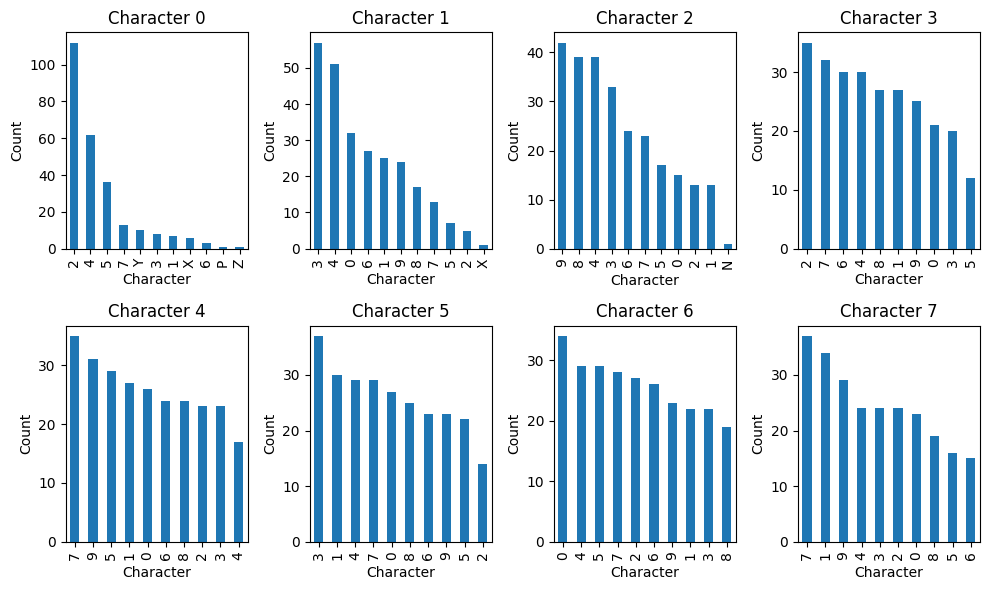

In [24]:
# make a histogram of the character of students per DNI character
plt.figure(figsize=(10, 6)) 
for i in range(8):  # Assuming DNI has 8 characters
    plt.subplot(2, 4, i + 1)
    dni_chars[f'DNI_char_{i}'].value_counts().plot(kind='bar')
    plt.title(f'Character {i}')
    plt.xlabel('Character')
    plt.ylabel('Count')
plt.tight_layout()
plt.show()

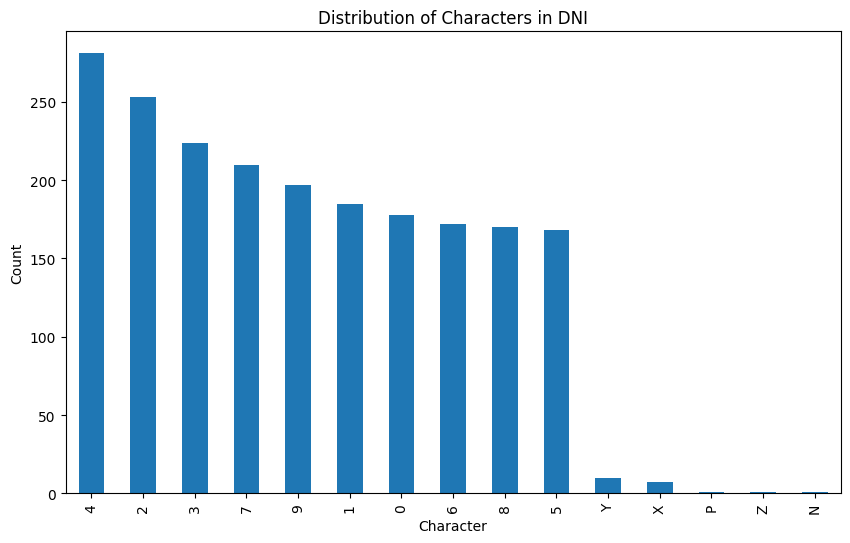

In [25]:
# histogram of destribution of the caracters in DNI 
plt.figure(figsize=(10, 6))
# Collect all characters from DNI_char_0 to DNI_char_7
all_chars = pd.concat([dni_chars[f'DNI_char_{i}'] for i in range(8)])

# Plot the grouped histogram
all_chars.value_counts().plot(kind='bar', figsize=(10, 6))
plt.title('Distribution of Characters in DNI')
plt.xlabel('Character')
plt.ylabel('Count')
plt.show()

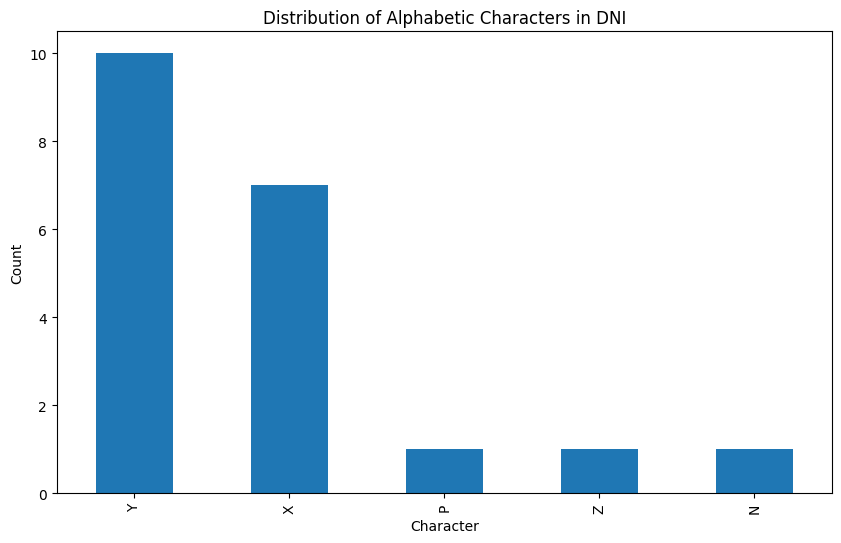

In [27]:
# Plot the distribution only the alphanumeric  characters in DNI
plt.figure(figsize=(10, 6))
# Filter out numeric characters, keep only alphabetic
alpha_chars = all_chars[all_chars.str.isalpha()]
alpha_chars.value_counts().plot(kind='bar', figsize=(10, 6))
plt.title('Distribution of Alphabetic Characters in DNI')
plt.xlabel('Character')
plt.ylabel('Count')
plt.show()

In [19]:
df_students_json = pd.read_json("./students.json")

In [20]:
df_students_json

,dni,nombre,apellidos
0,20851815,Borja,Abril Revert
1,26665047,Nader,Abu-Taha Sabsoub
2,49570057,Unai,Acedo Marzo
3,73606454,Sol,Agustina García
4,51780631,Pau,Ahuir Botella
...,...,...,...
255,Z807424,Filip Michal,Wolski
256,X7470664,Sandra,Yin
257,53947757,Marc,Zaragoza García
258,24421010,Jose,Zaragoza López
